# Compare cross decomposition methods: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cross_decomposition/plot_compare_cross_decomposition.py`
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([gallery page](https://scikit-learn.org/dev/auto_examples/cross_decomposition/plot_compare_cross_decomposition.html)).

**Scenario:** two covarying 4-feature blocks with two shared latent factors.
`PLSCanonical(n_components=2)` and `CCA(n_components=2)` are fitted on the first half and
project train and test halves (`transform(X, Y)`); `PLSRegression(n_components=3)` is fitted
on a multivariate response (PLS2, `coef_`, `predict`) and on a univariate one (PLS1, 1-D `y`).
Beyond the example, every learned attribute (`x_weights_`, `y_weights_`, `x_loadings_`,
`y_loadings_`, `x_rotations_`, `y_rotations_`, `coef_`, `intercept_`, `n_iter_`), single-block
`transform`, `inverse_transform`, `score` and `get_feature_names_out` are compared.

**Adaptations:** none to the data or estimators. The data are generated in Python with the
example's `np.random.default_rng(42)` and shared with Mojo as `.npy` files; Moxie returns paired
transforms as a `PairedScores` record (`x_scores`, `y_scores`) instead of a tuple. Figures use dpi 80.

**Determinism:** fully deterministic (fixed generator, `shuffle=False` split, deterministic
NIPALS power iterations). Numerical parity of every output is required.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cross_decomposition/compare")

## 1. scikit-learn (official example code)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
plt.rcParams["figure.dpi"] = 80

rng = np.random.default_rng(42)
n = 500
# 2 latents vars:
l1 = rng.normal(size=n)
l2 = rng.normal(size=n)

latents = np.array([l1, l1, l2, l2]).T
X = latents + rng.normal(size=(n, 4))
Y = latents + rng.normal(size=(n, 4))

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.5, shuffle=False)

print("Corr(X)")
print(np.round(np.corrcoef(X.T), 2))
print("Corr(Y)")
print(np.round(np.corrcoef(Y.T), 2))

Corr(X)
[[ 1.    0.48 -0.01  0.  ]
 [ 0.48  1.   -0.01  0.  ]
 [-0.01 -0.01  1.    0.49]
 [ 0.    0.    0.49  1.  ]]
Corr(Y)
[[ 1.    0.47  0.03  0.05]
 [ 0.47  1.    0.03 -0.01]
 [ 0.03  0.03  1.    0.5 ]
 [ 0.05 -0.01  0.5   1.  ]]


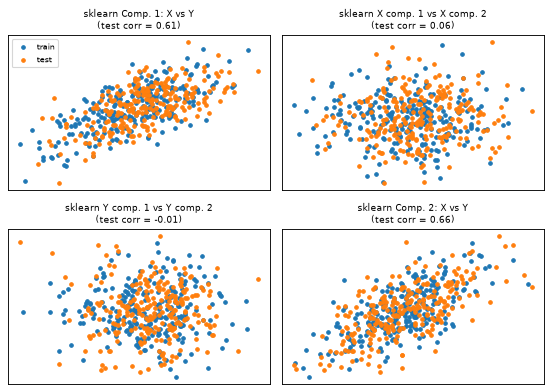

In [3]:
from sklearn.cross_decomposition import PLSCanonical

plsca = PLSCanonical(n_components=2)
plsca.fit(X_train, Y_train)
X_train_r, Y_train_r = plsca.transform(X_train, Y_train)
X_test_r, Y_test_r = plsca.transform(X_test, Y_test)


def scatter_matrix(axes, Xtr, Ytr, Xte, Yte, who):
    panels = [(axes[0, 0], Xtr[:, 0], Ytr[:, 0], Xte[:, 0], Yte[:, 0], "Comp. 1: X vs Y"),
              (axes[1, 1], Xtr[:, 1], Ytr[:, 1], Xte[:, 1], Yte[:, 1], "Comp. 2: X vs Y"),
              (axes[0, 1], Xtr[:, 0], Xtr[:, 1], Xte[:, 0], Xte[:, 1], "X comp. 1 vs X comp. 2"),
              (axes[1, 0], Ytr[:, 0], Ytr[:, 1], Yte[:, 0], Yte[:, 1], "Y comp. 1 vs Y comp. 2")]
    for ax, a, b, c, d, title in panels:
        ax.scatter(a, b, label="train", marker="o", s=10)
        ax.scatter(c, d, label="test", marker="o", s=10)
        ax.set_title(f"{who} {title}\n(test corr = {np.corrcoef(c, d)[0, 1]:.2f})", fontsize=8)
        ax.set_xticks(()); ax.set_yticks(())
    axes[0, 0].legend(loc="best", fontsize=7)


fig, axes = plt.subplots(2, 2, figsize=(7, 5))
scatter_matrix(axes, X_train_r, Y_train_r, X_test_r, Y_test_r, "sklearn")
plt.tight_layout(); plt.show()

In [4]:
from sklearn.cross_decomposition import PLSRegression

n = 1000
q = 3
p = 10
X2 = rng.normal(size=(n, p))
B = np.array([[1, 2] + [0] * (p - 2)] * q).T
# each Yj = 1*X1 + 2*X2 + noize
Y2 = np.dot(X2, B) + rng.normal(size=(n, q)) + 5

pls2 = PLSRegression(n_components=3)
pls2.fit(X2, Y2)
print("True B (such that: Y = XB + Err)")
print(B)
# compare pls2.coef_ with B
print("Estimated B")
print(np.round(pls2.coef_, 1))
pls2_pred = pls2.predict(X2)

n = 1000
p = 10
X1 = rng.normal(size=(n, p))
y1 = X1[:, 0] + 2 * X1[:, 1] + rng.normal(size=n) + 5
pls1 = PLSRegression(n_components=3)
pls1.fit(X1, y1)
# note that the number of components exceeds 1 (the dimension of y)
print("Estimated betas")
print(np.round(pls1.coef_, 1))
pls1_pred = pls1.predict(X1)

from sklearn.cross_decomposition import CCA

cca = CCA(n_components=2)
cca.fit(X_train, Y_train)
cca_X_train_r, cca_Y_train_r = cca.transform(X_train, Y_train)
cca_X_test_r, cca_Y_test_r = cca.transform(X_test, Y_test)

nb.share(X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test,
         X2=X2, Y2=Y2, X1=X1, y1=y1)

True B (such that: Y = XB + Err)
[[1 1 1]
 [2 2 2]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
Estimated B
[[ 1.   2.   0.  -0.   0.   0.   0.   0.   0.  -0. ]
 [ 1.   2.   0.  -0.  -0.  -0.  -0.  -0.1 -0.   0. ]
 [ 1.   2.   0.  -0.   0.   0.  -0.  -0.   0.   0. ]]
Estimated betas
[[ 1.   2.  -0.   0.  -0.   0.  -0.1  0.  -0.  -0. ]]


## 2. Moxie (native Mojo)

The same four fits through `moxie.cross_decomposition`. Learning, projection and prediction run
in Mojo; Python only supplied the arrays.

In [5]:
%%mojo compare
from numojo import NDArray
from moxie.cross_decomposition import PLSCanonical, PLSRegression, CCA
from moxie_nb_io import load, save, save_ints, save_strings, save_floats

comptime F64 = DType.float64


def save_fit(prefix: String, x_weights: NDArray[F64], y_weights: NDArray[F64],
             x_loadings: NDArray[F64], y_loadings: NDArray[F64],
             x_rotations: NDArray[F64], y_rotations: NDArray[F64],
             coef: NDArray[F64], intercept: NDArray[F64], n_iter: List[Int]) raises:
    save(prefix + "x_weights", x_weights)
    save(prefix + "y_weights", y_weights)
    save(prefix + "x_loadings", x_loadings)
    save(prefix + "y_loadings", y_loadings)
    save(prefix + "x_rotations", x_rotations)
    save(prefix + "y_rotations", y_rotations)
    save(prefix + "coef", coef)
    save(prefix + "intercept", intercept)
    save_ints(prefix + "n_iter", n_iter)


def main() raises:
    var X_train = load("X_train")
    var Y_train = load("Y_train")
    var X_test = load("X_test")
    var Y_test = load("Y_test")

    var plsca = PLSCanonical(n_components=2)
    _ = plsca.fit(X_train, Y_train)
    var tr = plsca.transform(X_train, Y_train)
    var te = plsca.transform(X_test, Y_test)
    save("plsca_X_train_r", tr.x_scores)
    save("plsca_Y_train_r", tr.y_scores)
    save("plsca_X_test_r", te.x_scores)
    save("plsca_Y_test_r", te.y_scores)
    save("plsca_X_only", plsca.transform(X_test))
    var back = plsca.inverse_transform(te.x_scores, te.y_scores)
    save("plsca_inv_X", back.x_scores)
    save("plsca_inv_Y", back.y_scores)
    save("plsca_pred", plsca.predict(X_test))
    save_floats("plsca_score", [plsca.score(X_test, Y_test)])
    save_strings("plsca_names", plsca.get_feature_names_out())
    save_fit("plsca_", plsca.x_weights_, plsca.y_weights_, plsca.x_loadings_, plsca.y_loadings_,
             plsca.x_rotations_, plsca.y_rotations_, plsca.coef_, plsca.intercept_, plsca.n_iter_)

    var X2 = load("X2")
    var Y2 = load("Y2")
    var pls2 = PLSRegression(n_components=3)
    _ = pls2.fit(X2, Y2)
    save("pls2_pred", pls2.predict(X2))
    save("pls2_x_scores", pls2.x_scores_)
    save("pls2_y_scores", pls2.y_scores_)
    save_floats("pls2_score", [pls2.score(X2, Y2)])
    save_fit("pls2_", pls2.x_weights_, pls2.y_weights_, pls2.x_loadings_, pls2.y_loadings_,
             pls2.x_rotations_, pls2.y_rotations_, pls2.coef_, pls2.intercept_, pls2.n_iter_)

    var X1 = load("X1")
    var y1 = load("y1")
    var pls1 = PLSRegression(n_components=3)
    _ = pls1.fit(X1, y1)
    save("pls1_pred", pls1.predict(X1))
    save("pls1_inv_X", pls1.inverse_transform(pls1.transform(X1)))
    save_fit("pls1_", pls1.x_weights_, pls1.y_weights_, pls1.x_loadings_, pls1.y_loadings_,
             pls1.x_rotations_, pls1.y_rotations_, pls1.coef_, pls1.intercept_, pls1.n_iter_)

    var cca = CCA(n_components=2)
    _ = cca.fit(X_train, Y_train)
    var ctr = cca.transform(X_train, Y_train)
    var cte = cca.transform(X_test, Y_test)
    save("cca_X_train_r", ctr.x_scores)
    save("cca_Y_train_r", ctr.y_scores)
    save("cca_X_test_r", cte.x_scores)
    save("cca_Y_test_r", cte.y_scores)
    save_strings("cca_names", cca.get_feature_names_out())
    save_fit("cca_", cca.x_weights_, cca.y_weights_, cca.x_loadings_, cca.y_loadings_,
             cca.x_rotations_, cca.y_rotations_, cca.coef_, cca.intercept_, cca.n_iter_)
    print("PLS2 estimated B (coef_):")
    print(pls2.coef_)
    print("CCA n_iter_:", cca.n_iter_[0], cca.n_iter_[1], "diagnostics:", len(cca.diagnostics_))

PLS2 estimated B (coef_):
[[1.0326 1.9916 ... 0.0183 -0.0242]
[0.9986 1.9877 ... -0.0148 0.0388]
[0.9923 1.9541 ... 0.0244 0.0123]]
2D-array  Shape: (3, 10)  Strides: (10, 1)  DType: f64  order: C  own data: True
CCA n_iter_: 47 3 diagnostics: 0


## 3. Side by side and parity

Tolerances. Both sides run the same Float64 algorithm (same centering, NIPALS iteration count,
`_svd_flip_1d` sign rule and pseudoinverse cutoffs); differences come only from summation order
(BLAS vs scalar loops) and the Jacobi vs LAPACK SVD inside `pinv`. The family parity suite
measures scaled errors <= 1e-13 on well-conditioned data, so `rtol=1e-9, atol=1e-10` leaves
three orders of margin while catching any sign, branch or algorithm difference (all O(1)).
CCA's mode-B weights go through two data pseudoinverses and stop at `tol=1e-6`, so its
attributes get `atol=1e-8`. Signs are compared exactly: no sign-insensitive comparison is used.

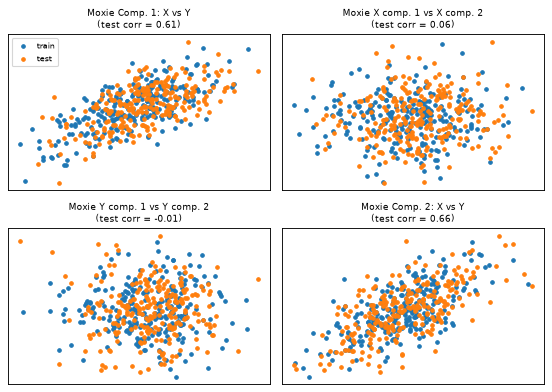

In [6]:
mx = nb.results["compare"]
fig, axes = plt.subplots(2, 2, figsize=(7, 5))
scatter_matrix(axes, mx["plsca_X_train_r"], mx["plsca_Y_train_r"], mx["plsca_X_test_r"], mx["plsca_Y_test_r"], "Moxie")
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=np.round(pls2.coef_, 1), moxie=np.round(mx["pls2_coef"], 1))
moxie_nb.side_by_side(sklearn=np.round(pls1.coef_, 1), moxie=np.round(mx["pls1_coef"], 1))

In [7]:
tight = dict(rtol=1e-9, atol=1e-10, reason="same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ")
attrs = ["x_weights_", "y_weights_", "x_loadings_", "y_loadings_", "x_rotations_", "y_rotations_", "coef_", "intercept_"]
for prefix, est in [("plsca", plsca), ("pls2", pls2), ("pls1", pls1)]:
    for a in attrs:
        nb.compare(f"{prefix}.{a}", getattr(est, a), mx[f"{prefix}_{a[:-1]}"], **tight)
    nb.compare(f"{prefix}.n_iter_", np.array(est.n_iter_), mx[f"{prefix}_n_iter"], exact=True)
for a in attrs:
    nb.compare(f"cca.{a}", getattr(cca, a), mx[f"cca_{a[:-1]}"], rtol=1e-8, atol=1e-8,
               reason="mode B: two data pseudoinverses plus tol=1e-6 stopping amplify rounding")
nb.compare("cca.n_iter_", np.array(cca.n_iter_), mx["cca_n_iter"], exact=True)

nb.compare("plsca.transform(X_train, Y_train)[0]", X_train_r, mx["plsca_X_train_r"], **tight)
nb.compare("plsca.transform(X_train, Y_train)[1]", Y_train_r, mx["plsca_Y_train_r"], **tight)
nb.compare("plsca.transform(X_test, Y_test)[0]", X_test_r, mx["plsca_X_test_r"], **tight)
nb.compare("plsca.transform(X_test, Y_test)[1]", Y_test_r, mx["plsca_Y_test_r"], **tight)
nb.compare("plsca.transform(X_test)", plsca.transform(X_test), mx["plsca_X_only"], **tight)
inv_X, inv_Y = plsca.inverse_transform(X_test_r, Y_test_r)
nb.compare("plsca.inverse_transform(X_r, Y_r)[0]", inv_X, mx["plsca_inv_X"], **tight)
nb.compare("plsca.inverse_transform(X_r, Y_r)[1]", inv_Y, mx["plsca_inv_Y"], **tight)
nb.compare("plsca.predict(X_test)", plsca.predict(X_test), mx["plsca_pred"], **tight)
nb.compare("plsca.score(X_test, Y_test)", plsca.score(X_test, Y_test), mx["plsca_score"][0], **tight)
nb.compare("plsca.get_feature_names_out()", list(plsca.get_feature_names_out()), list(mx["plsca_names"]), exact=True)

nb.compare("pls2.predict(X)", pls2_pred, mx["pls2_pred"], **tight)
nb.compare("pls2.x_scores_", pls2.x_scores_, mx["pls2_x_scores"], **tight)
nb.compare("pls2.y_scores_", pls2.y_scores_, mx["pls2_y_scores"], **tight)
nb.compare("pls2.score(X, Y)", pls2.score(X2, Y2), mx["pls2_score"][0], **tight)
nb.compare("pls1.predict(X) (1-D)", pls1_pred, mx["pls1_pred"], **tight)
nb.compare("pls1.predict ndim", pls1_pred.ndim, mx["pls1_pred"].ndim, exact=True)
nb.compare("pls1.inverse_transform(transform(X))", pls1.inverse_transform(pls1.transform(X1)), mx["pls1_inv_X"], **tight)

loose = dict(rtol=1e-8, atol=1e-8, reason="mode B pseudoinverses (see above)")
nb.compare("cca.transform(X_train, Y_train)[0]", cca_X_train_r, mx["cca_X_train_r"], **loose)
nb.compare("cca.transform(X_train, Y_train)[1]", cca_Y_train_r, mx["cca_Y_train_r"], **loose)
nb.compare("cca.transform(X_test, Y_test)[0]", cca_X_test_r, mx["cca_X_test_r"], **loose)
nb.compare("cca.transform(X_test, Y_test)[1]", cca_Y_test_r, mx["cca_Y_test_r"], **loose)
nb.compare("cca.get_feature_names_out()", list(cca.get_feature_names_out()), list(mx["cca_names"]), exact=True)
for k in range(2):
    nb.compare(f"test corr comp {k + 1} (plot title)", np.corrcoef(X_test_r[:, k], Y_test_r[:, k])[0, 1],
               np.corrcoef(mx["plsca_X_test_r"][:, k], mx["plsca_Y_test_r"][:, k])[0, 1], **tight)

In [8]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
plsca.x_weights_,PASS,"(4, 2)","(4, 2)",2.78e-16,9.8e-16,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.y_weights_,PASS,"(4, 2)","(4, 2)",3.33e-16,5.02e-16,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.x_loadings_,PASS,"(4, 2)","(4, 2)",5.55e-16,1.3e-15,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.y_loadings_,PASS,"(4, 2)","(4, 2)",6.66e-16,1.03e-15,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.x_rotations_,PASS,"(4, 2)","(4, 2)",5.55e-16,1.58e-15,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.y_rotations_,PASS,"(4, 2)","(4, 2)",5e-16,1.28e-15,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.coef_,PASS,"(4, 4)","(4, 4)",6.66e-16,1.66e-13,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.intercept_,PASS,"(4,)","(4,)",0,0,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
plsca.n_iter_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
pls2.x_weights_,PASS,"(10, 3)","(10, 3)",1.14e-15,1.69e-14,"rtol=1e-09, atol=1e-10",,same Float64 algorithm; summation order and Jacobi vs LAPACK pinv differ
